Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).
First 5 rows:
               country  child_mort  exports  health  imports  income  \
0          Afghanistan        90.2     10.0    7.58     44.9    1610   
1              Albania        16.6     28.0    6.55     48.6    9930   
2              Algeria        27.3     38.4    4.17     31.4   12900   
3               Angola       119.0     62.3    2.85     42.9    5900   
4  Antigua and Barbuda        10.3     45.5    6.03     58.9   19100   

   inflation  life_expec  total_fer   gdpp  
0       9.44        56.2       5.82    553  
1       4.49        76.3       1.65   4090  
2      16.10        76.5       2.89   4460  
3      22.40        60.1       6.16   3530  
4       1.44        76.8       2.13  12200  

Selected Features:
   child_mort  income  life_expec
0        90.2    1610        56.2
1        16.6    9930        76.3
2        27.3   12900        7

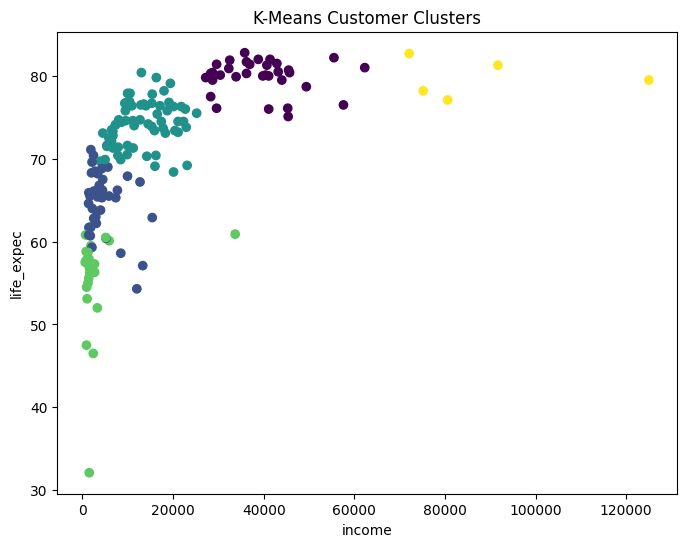


Hierarchical Clustering Results:
               country  child_mort  income  life_expec   gdpp  \
0          Afghanistan        90.2    1610        56.2    553   
1              Albania        16.6    9930        76.3   4090   
2              Algeria        27.3   12900        76.5   4460   
3               Angola       119.0    5900        60.1   3530   
4  Antigua and Barbuda        10.3   19100        76.8  12200   
5            Argentina        14.5   18700        75.8  10300   
6              Armenia        18.1    6700        73.3   3220   
7            Australia         4.8   41400        82.0  51900   
8              Austria         4.3   43200        80.5  46900   
9           Azerbaijan        39.2   16000        69.1   5840   

   Hierarchical_Cluster  
0                     0  
1                     2  
2                     2  
3                     0  
4                     2  
5                     2  
6                     2  
7                     4  
8               

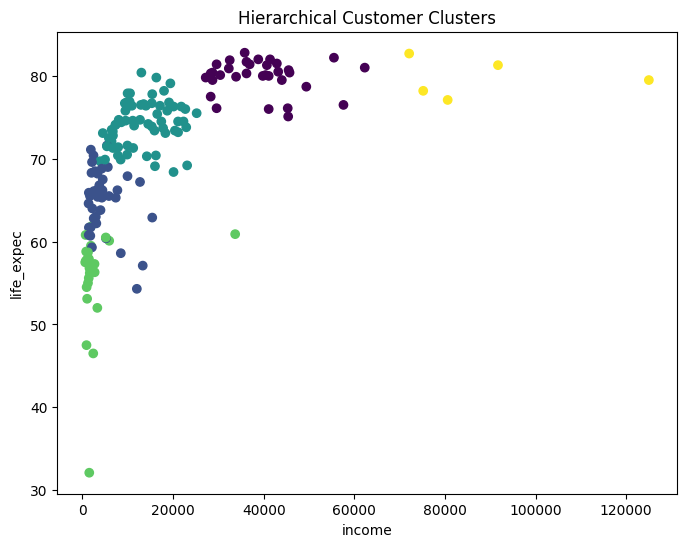


Explained Variance:
[0.78714882 0.17748617]

Total Variance Explained:
0.9646349873226875


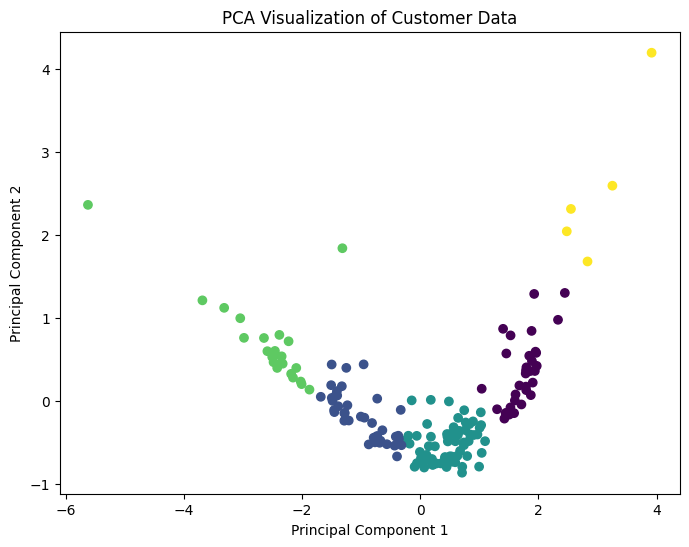

In [ ]:
# ============================================
# K-Means, Hierarchical Clustering, and PCA
# Kaggle Mall Customers Dataset
# ============================================

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA


# ============================================
# 2. Mount Google Drive
# ============================================

drive.mount('/content/drive/')


# ============================================
# 3. Read the Kaggle dataset
# ============================================


file_path = "/content/drive/My Drive/datasets/Country-data.csv"


df = pd.read_csv(file_path)

print("First 5 rows:")
print(df.head())


# ============================================
# 4. Select features
# ============================================

X = df[
    [
        'child_mort',
        'income',
        'life_expec'
    ]
]

print("\nSelected Features:")
print(X.head())


# ============================================
# 5. Standardize the data
# ============================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ============================================
# 6. K-MEANS CLUSTERING
# ============================================

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)


print("\nK-Means Results:")
print(df[
    [
        'country',
        'child_mort',
        'income',
        'life_expec',
        'KMeans_Cluster'
    ]
].head(10))


# ============================================
# 7. Plot K-Means
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    df['income'],
    df['life_expec'],
    c=df['KMeans_Cluster']
)

plt.xlabel('income')
plt.ylabel('life_expec')
plt.title('K-Means Customer Clusters')

plt.show()


# ============================================
# 8. HIERARCHICAL CLUSTERING
# ============================================

hierarchical = AgglomerativeClustering(
    n_clusters=5
)

df['Hierarchical_Cluster'] = hierarchical.fit_predict(
    X_scaled
)


print("\nHierarchical Clustering Results:")
print(df[
    [
        'country',
        'child_mort',
        'income',
        'life_expec',
        'gdpp',
        'Hierarchical_Cluster'
    ]
].head(10))


# ============================================
# 9. Plot Hierarchical Clustering
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    df['income'],
    df['life_expec'],
    c=df['KMeans_Cluster']
)

plt.xlabel('income')
plt.ylabel('life_expec')
plt.title('Hierarchical Customer Clusters')

plt.show()


# ============================================
# 10. PCA
# ============================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)


# Add PCA results to DataFrame
df['PC1'] = X_pca[:, 0]
df['PC2'] = X_pca[:, 1]


# ============================================
# 11. Explained Variance
# ============================================

print("\nExplained Variance:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")
print(pca.explained_variance_ratio_.sum())


# ============================================
# 12. Plot PCA
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    df['PC1'],
    df['PC2'],
    c=df['KMeans_Cluster']
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Visualization of Customer Data')

plt.show()

### Part 1
Dataset Name: Unsupervised Learning on Country Data

Dataset Kaggle Link: https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data

Description about this dataset: This datatset contains 167 countries, and it includes 10 possible features, like for example income, mortality rates, and life expectancy.

Number of Rows: 167

Number of Columns: 10

---

### Part 2

Done, run the code.

---

### Part 3
Why did you pick these features?

I selected child_mort, income, and life_expec because they help show the main differences between all the countries. These features can help identify which contries have similar economic and health conditions.

Why is standardization important before culstering?

Standardization is very important because the features have different scales.Like for example, income can be in the hundreds of thousands even millions, while life expectancy is around 50 years to 85 years. Standardization puts those features into a similar scale, so that the income cannot have much influence just because that specific category has high numbers, it puts them at a similar scale.

---

### Part 4
Explain why you selected that number.

The default was 5 clusters so I kept it the same, it also helps separate the countries into several groups based off of their similarities, having more than 5 seems to be an overkill.This allows me to see and compare the different economic conditions and health conditions, instead of just relying on two groups.

Briefly explain what the clusters represent in the context of your dataset.

These clusters represent groups of countries wiht similar income, child mortality rates, and life expectancy. Like for example, Afghanistan and Angola were placed in the same cluster, while on the other hand Australia and Austria were placed in the same groups in another cluster. This just goes to show how countries are with different conditions can be separated into different groups.

---

### Part 5
Explain whether the groups are similar to or different from the K-Means results.

The results from the hierarchical clustering were the similar to K-Means results. Both methods grouped the countries based on income, child mortality, and life expectancy. Like how K-Means did, Afghanistan and Angola were grouped together, and Australia and Austria were grouped together in both of the methods. However, some countries may be placed in differnet clusters because the two methods use different ways to group the data. Both methods showed similar patterns between all the countries.

---

### Part 6

Explain what the PCA plot shows.

I used PCA to reduce my three selected features, into two principal components. PC1 explained 78.71% of the variance, and PC2 explained 17.75%. Together they both explained a total of 96.46% of variance. The PCA plot shows the countries in two dimensions using their K-Means clusters, it helps visualize how a country with similiar economic and health conditions are group together. PCA makes the data easier to understand while also keeping most of the information original.

---

### Part 7

1. What did the K-Means clusters reveal?

The K-Means clusters reveals those countries that can be grouped based on their income, child mortality rates, and life expectancy. Like how in model, it grouped Afghanistan and Angola together, and then how it group Australia and Austria together, because both of those groups have different economic conditions and even health conditions.

2. What did hierarchical clustering reveal?

The hierarchical clustering reveals how similar the results were between this and K-Means. Both methods grouped the same countries with the similar characteristics, although some countries mau be placed in a different cluster because of how this method works different than the K-Means method.

3. How much variation was captured by PC1 and PC2?

PC1 captured 78.71% of the variation, while PC2 captured 17.75% of the other variation. Both of them added up comes to 96.46% of the total variation.

4. What did PCA help you understand about the dataset?

PCA helped me understand and visualize the similarities and differences between countries in a two dimensional graph. It had made it much more easier to see the clusters while also keeping most of the information original from the three features.